# 고장 이벤트별 원본 센서 탐색

실제 V3 원본 인덱스와 집계만 사용합니다. 원본·V1/V2는 읽기 전용입니다. 대시보드는 `dashboard/app.py`로 실행합니다.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.common import TABLES, CFG
from src.detail import get_detail
from src.visuals import detail_figure
assert Path(sys.executable).resolve() == Path(CFG['python']).resolve()
print('실제 실행 Python:', sys.executable)
print('시간: raw / 연구 진단용 / 모델 학습 없음')


실제 실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
시간: raw / 연구 진단용 / 모델 학습 없음


In [2]:
tool = '03M02'
events = pd.read_parquet(TABLES/'fault_event_summary.parquet')
display(events[events.Tool.eq(tool)].head(20))

,Index,event_id,Tool,fault_type,fault_name,fault_time,tagged,source_rows,source_row_count,pre_60,...,warning_sensor_300,warning_sensor_600,warning_sensor_1800,sensor_pre1800,coverage_pre60,coverage_pre300,coverage_pre900,last_sensor_lag,label_status,exclusion_reason_C_h600
268,268,03M02-low-c37936a41279,03M02,low,FlowCool Pressure Dropped Below Limit,3326152.0,False,03_M02_train_fault_data.csv:2,1,0,...,0,0,99,True,0.000000,0.000000,0.000000,1406.0,POS 후보 존재,현재 센서 없음/오래됨/충돌
269,269,03M02-low-a541bb296b11,03M02,low,FlowCool Pressure Dropped Below Limit,3780688.0,False,03_M02_train_fault_data.csv:3,1,0,...,0,0,281,True,0.000000,0.000000,0.248889,678.0,POS 후보 존재,현재 센서 없음/오래됨/충돌
270,270,03M02-low-a415501ca67e,03M02,low,FlowCool Pressure Dropped Below Limit,3961378.0,False,03_M02_train_fault_data.csv:4,1,0,...,0,67,367,True,0.000000,0.000000,0.626667,336.0,POS 후보 존재,보존됨
271,271,03M02-low-fa2c15592d5a,03M02,low,FlowCool Pressure Dropped Below Limit,4528896.0,False,03_M02_train_fault_data.csv:5;03_M02_train_fau...,2,0,...,0,0,0,False,0.000000,0.000000,0.000000,4936.0,POS 후보 존재,현재 센서 없음/오래됨/충돌
272,272,03M02-high-7ba2d4a006ee,03M02,high,Flowcool Pressure Too High Check Flowcool Pump,4984318.0,False,03_M02_train_fault_data.csv:7;03_M02_train_fau...,2,0,...,0,0,0,False,0.000000,0.000000,0.000000,91372.0,POS 후보 존재,현재 센서 없음/오래됨/충돌
273,273,03M02-low-5dceeb25452b,03M02,low,FlowCool Pressure Dropped Below Limit,5076390.0,False,03_M02_train_fault_data.csv:9;03_M02_train_fau...,2,0,...,0,0,182,True,0.000000,0.000000,0.000000,1074.0,POS 후보 존재,현재 센서 없음/오래됨/충돌
274,274,03M02-low-d58f88774e8e,03M02,low,FlowCool Pressure Dropped Below Limit,5120600.0,False,03_M02_train_fault_data.csv:11;03_M02_train_fa...,2,0,...,4,79,278,True,0.000000,0.040000,0.560000,288.0,POS 후보 존재,900 raw 이력 부족
275,275,03M02-high-30905f1e029f,03M02,high,Flowcool Pressure Too High Check Flowcool Pump,5128078.0,False,03_M02_train_fault_data.csv:13;03_M02_train_fa...,2,15,...,60,135,435,True,1.000000,1.000000,1.000000,2.0,POS 후보 존재,보존됨
276,276,03M02-high-f040fbec61b0,03M02,high,Flowcool Pressure Too High Check Flowcool Pump,6040840.0,False,03_M02_train_fault_data.csv:15,1,0,...,0,0,0,False,0.000000,0.000000,0.000000,8160.0,POS 후보 존재,현재 센서 없음/오래됨/충돌
277,277,03M02-low-92ee94b49a7e,03M02,low,FlowCool Pressure Dropped Below Limit,6052526.0,False,03_M02_train_fault_data.csv:16,1,0,...,0,0,0,False,0.000000,0.000000,0.000000,19846.0,POS 후보 존재,현재 센서 없음/오래됨/충돌


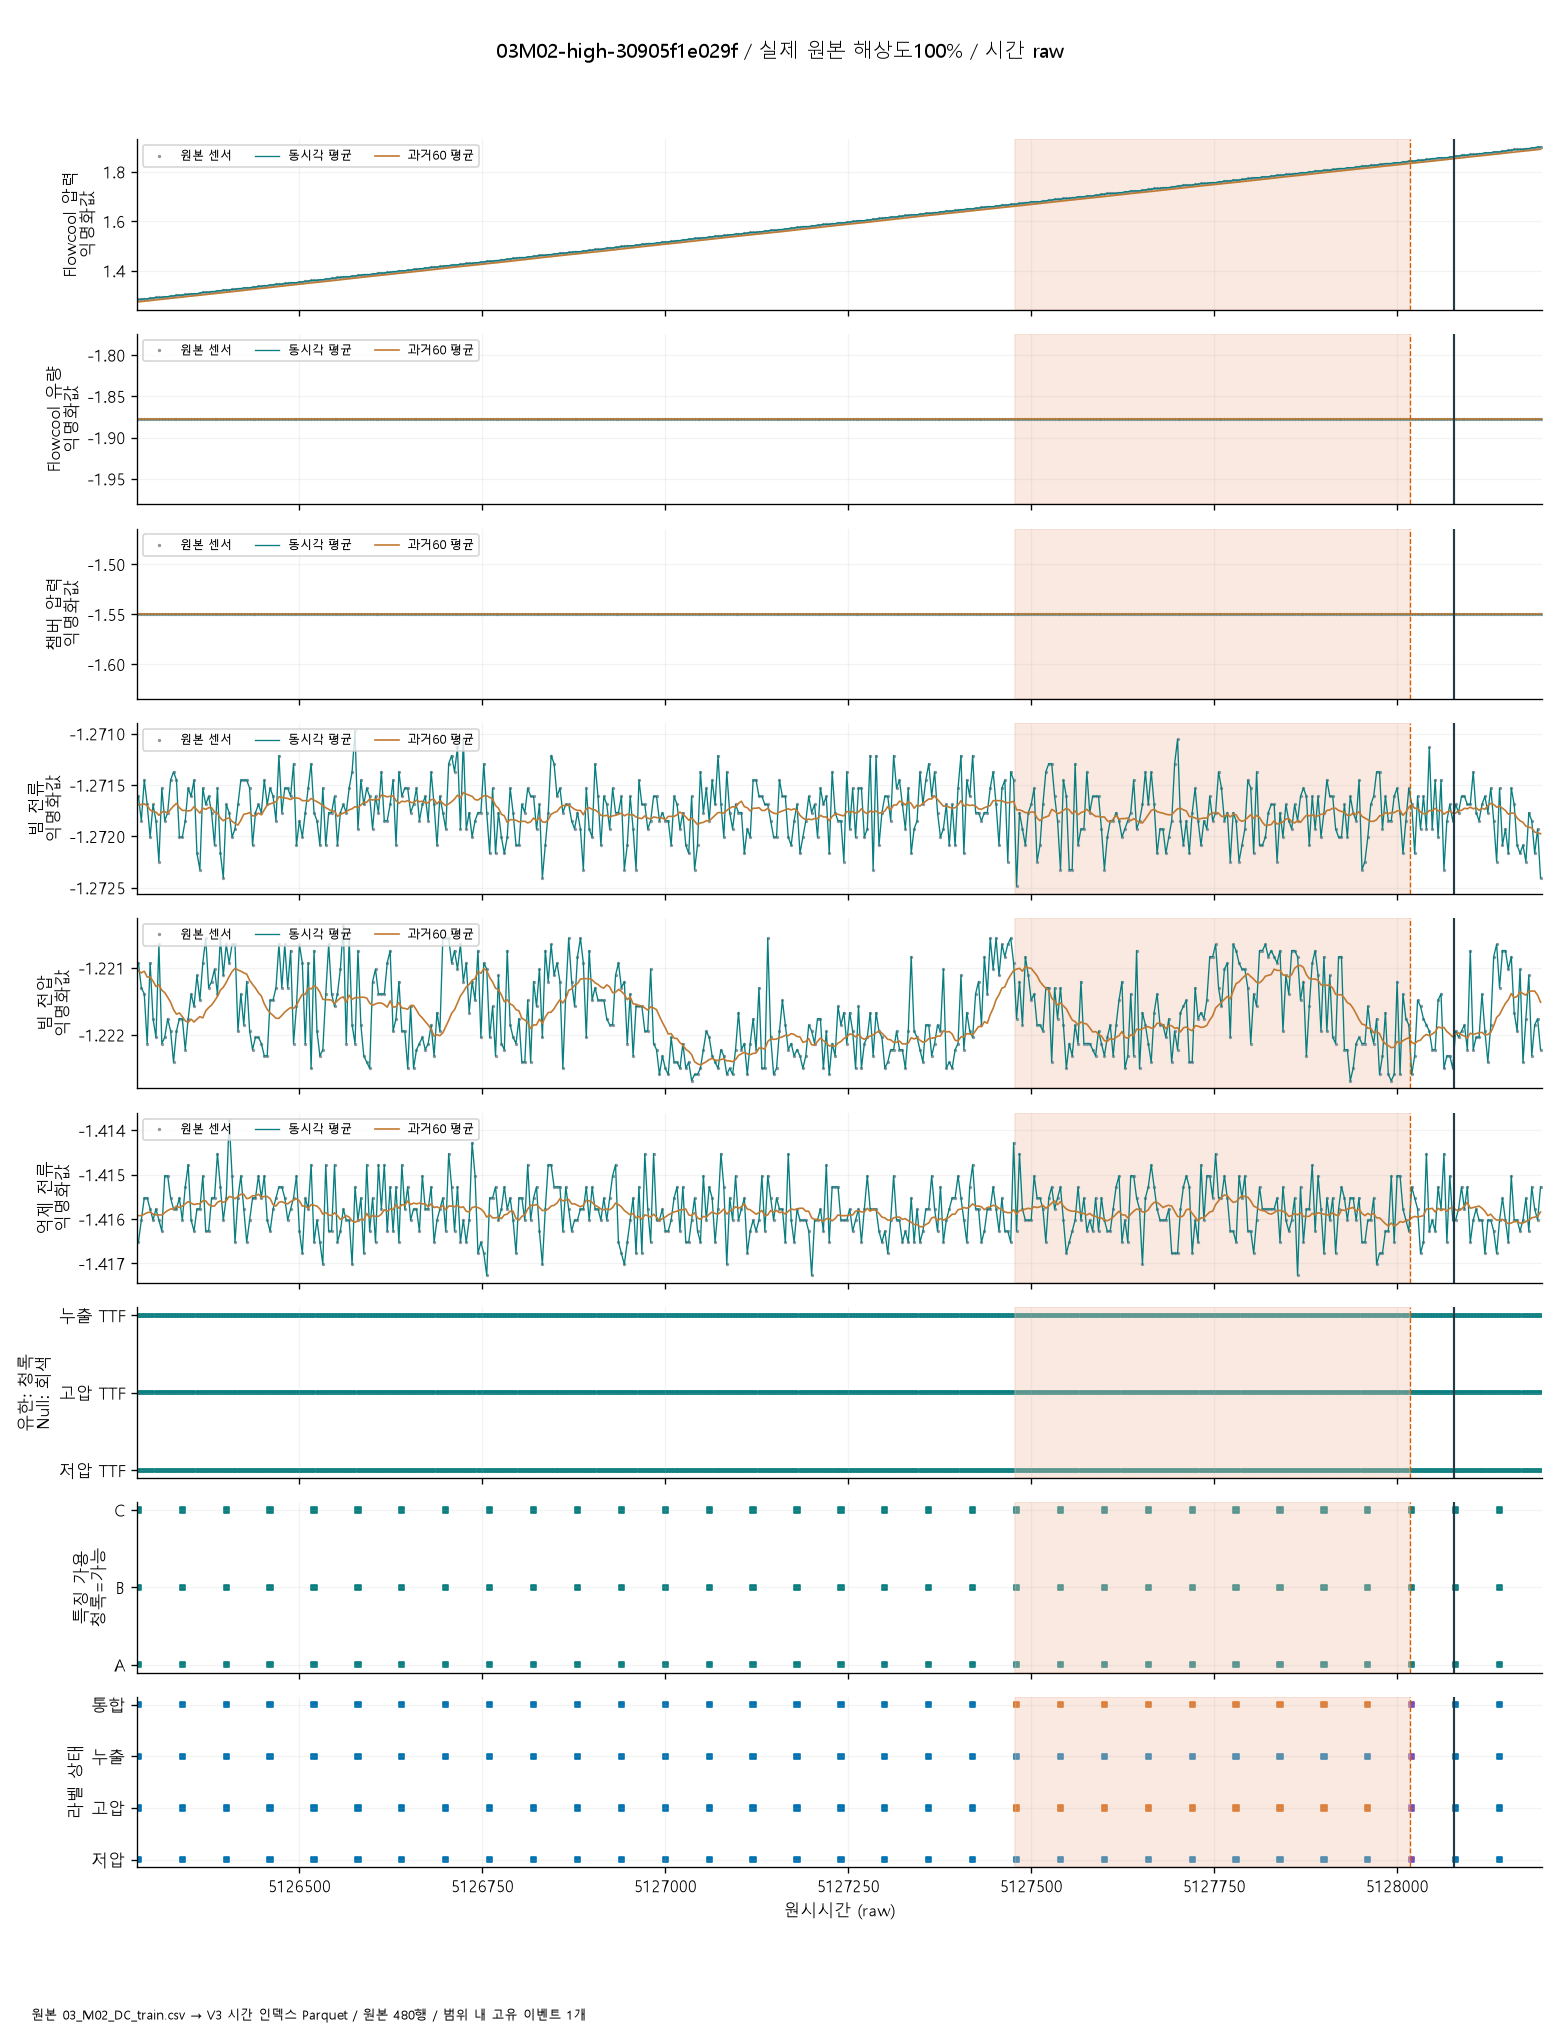

In [3]:
# event_id와 lookback_raw를 변경하면 해당 원본 구간을 다시 읽습니다.
event = events[events.Tool.eq(tool) & events.coverage_pre300.ge(.9)].iloc[0]
event_id = event.event_id
lookback_raw = 1800
detail = get_detail(tool,event.fault_time-lookback_raw,event.fault_time+120,event_id)
fig = detail_figure(detail)
fig.suptitle(event_id+' / 실제 원본 해상도100% / 시간 raw')
fig.text(.02,.01,detail['source']+' / 원본 '+str(detail['raw_rows'])+'행 / 범위 내 고유 이벤트 '+str(detail['unique_events_in_range'])+'개',fontsize=8)
fig.tight_layout(rect=(0,.05,1,.96))
import io
buffer = io.BytesIO()
fig.savefig(buffer,format='png',dpi=120)
display(Image(data=buffer.getvalue()))
import matplotlib.pyplot as plt
plt.close(fig)

In [4]:
display(pd.DataFrame(detail['exclusions']))
display(pd.DataFrame(detail['anchor_table']).head(20))
display(Markdown('고장 이후는 참고 표시입니다. 정지 시각 이전의 변화가 인과관계나 실제 이상 시작을 입증하지는 않습니다.'))

,event_id,Tool,fault_type,fault_time,policy,H,feature_set,warning_anchors,label_positive_anchors,usable_positive_anchors,current_available,history_60,history_300,history_900,imminent_excluded,preserved,reason
0,03M02-high-30905f1e029f,03M02,high,5128078.0,conservative,600,C,9,9,9,9,9,9,9,0,True,보존됨


,time,last_observation,current_lag,n_60,n_300,n_900,coverage_60,coverage_300,coverage_900,A_available,...,recipe_step,low,low_evidence,high,high_evidence,leak,leak_evidence,any,any_evidence,candidate_reason
0,5126280,5126280.0,0.0,15,75,225,1.0,1.0,1.0,True,...,1.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,해당 정책의 연구 후보
1,5126340,5126340.0,0.0,15,75,225,1.0,1.0,1.0,True,...,1.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,해당 정책의 연구 후보
2,5126400,5126400.0,0.0,15,75,225,1.0,1.0,1.0,True,...,1.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,해당 정책의 연구 후보
3,5126460,5126460.0,0.0,15,75,225,1.0,1.0,1.0,True,...,1.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,해당 정책의 연구 후보
4,5126520,5126520.0,0.0,15,75,225,1.0,1.0,1.0,True,...,1.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,해당 정책의 연구 후보
5,5126580,5126580.0,0.0,15,75,225,1.0,1.0,1.0,True,...,1.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,해당 정책의 연구 후보
6,5126640,5126640.0,0.0,15,75,225,1.0,1.0,1.0,True,...,1.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,해당 정책의 연구 후보
7,5126700,5126700.0,0.0,15,75,225,1.0,1.0,1.0,True,...,1.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,해당 정책의 연구 후보
8,5126760,5126760.0,0.0,15,75,225,1.0,1.0,1.0,True,...,1.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,해당 정책의 연구 후보
9,5126820,5126820.0,0.0,15,75,225,1.0,1.0,1.0,True,...,1.0,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,검증 TTF/다음 고장이 H 밖,NEG,모든 유형이 해당 정책상 음성,해당 정책의 연구 후보


고장 이후는 참고 표시입니다. 정지 시각 이전의 변화가 인과관계나 실제 이상 시작을 입증하지는 않습니다.